# Part 3, step 1 – import and compare samples (tutorial 3-2 + 3-3)
Run each cell with **Shift+Enter**; plots appear below the cell.

In [1]:
library(tidyverse)
options(repr.plot.width = 12, repr.plot.height = 5)   # plot size in the notebook
# White plot background (otherwise VS Code dark theme shows through)
setHook("before.plot.new", function() par(bg = "white"))
theme_update(plot.background = element_rect(fill = "white", colour = NA))

base <- "~/Documents/claude/Claude/Systems Genomics/RNAseq_aging/for_teammates"

expr <- as.matrix(read.csv(file.path(base, "rsem_tpm.csv.gz"), row.names = 1, check.names = FALSE))

meta <- read.csv(file.path(base, "samples.csv"))
rownames(meta) <- meta$SRR
expr <- expr[, meta$SRR]
stopifnot(all(colnames(expr) == meta$SRR))

meta_genes <- read.csv(file.path(base, "genes_M39.csv"))
meta_genes <- data.frame(gene_id = rownames(expr)) %>%
  left_join(meta_genes, by = "gene_id")

dim(expr)
table(meta$group)

Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘purrr’ was built under R version 4.4.3”
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.2     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


[1] 78289    27


       aDR aging 18mo aging 21mo  aging 3mo         AL        PBS        YMP 
         5          4          4          4          4          3          3 

## How many genes are expressed?

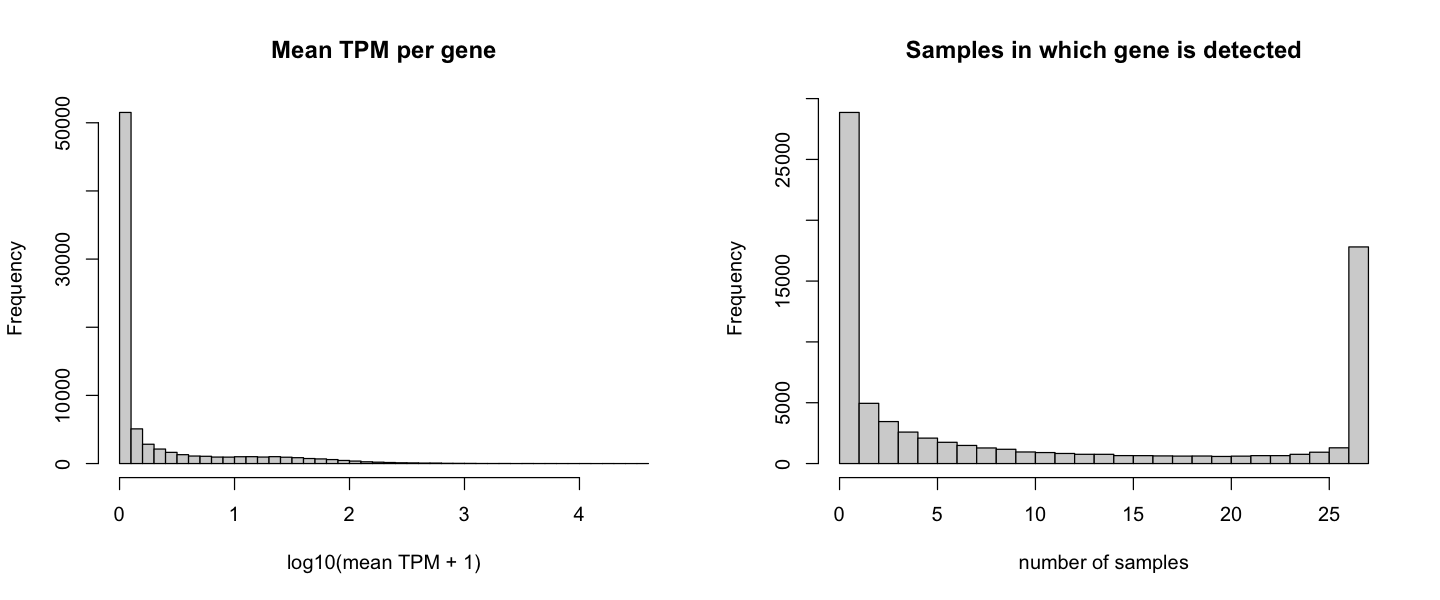

In [2]:
avg_expr <- rowMeans(expr)
num_det  <- rowSums(expr > 0)

layout(matrix(1:2, nrow = 1))
hist(log10(avg_expr + 1), breaks = 50, main = "Mean TPM per gene", xlab = "log10(mean TPM + 1)")
hist(num_det, breaks = 0:27, main = "Samples in which gene is detected", xlab = "number of samples")

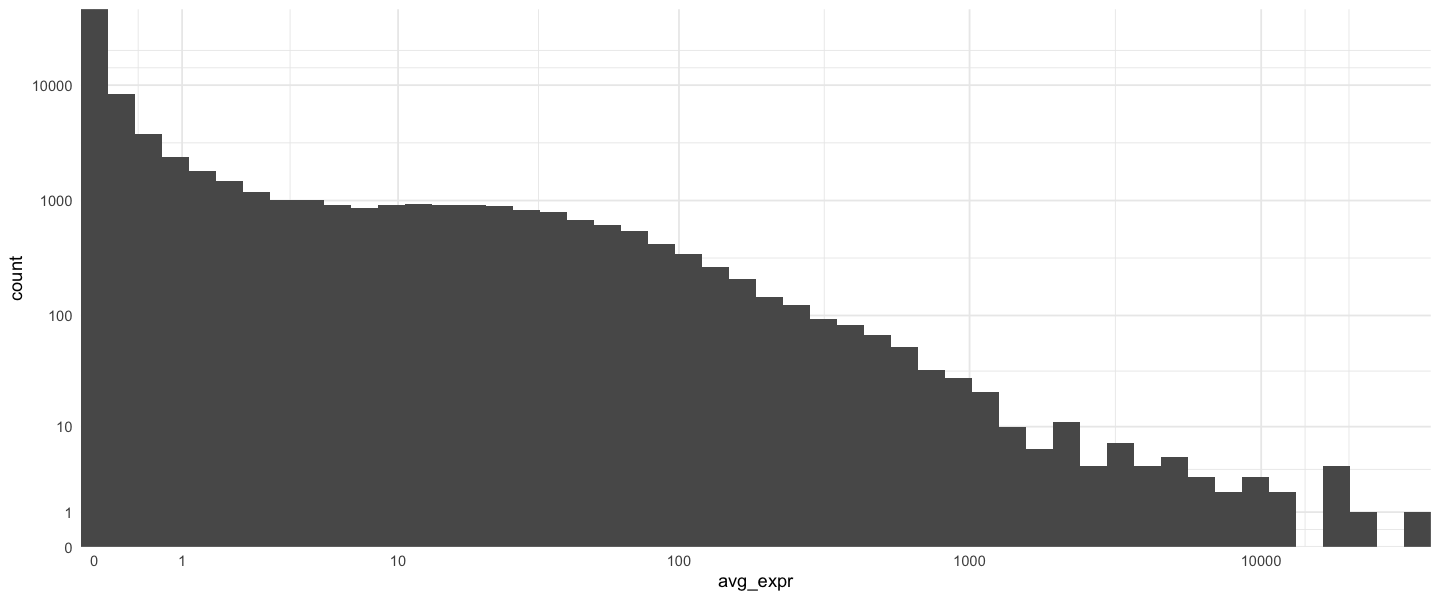

In [3]:
ggplot(data.frame(avg_expr), aes(x = avg_expr)) +
  geom_histogram(bins = 50) +
  scale_x_continuous(breaks = c(0,1,10,100,1000,10000), trans = "log1p", expand = c(0,0)) +
  scale_y_continuous(breaks = c(0,1,10,100,1000,10000), trans = "log1p", expand = c(0,0)) +
  theme_minimal()

## Keep only expressed genes
Detected in at least half the samples, or mean TPM ≥ 1.

In [4]:
expressed <- rowMeans(expr > 0) >= 0.5 | rowMeans(expr) >= 1
meta_genes$expressed <- expressed
sum(expressed)

[1] 28147

## Correlation and hierarchical clustering

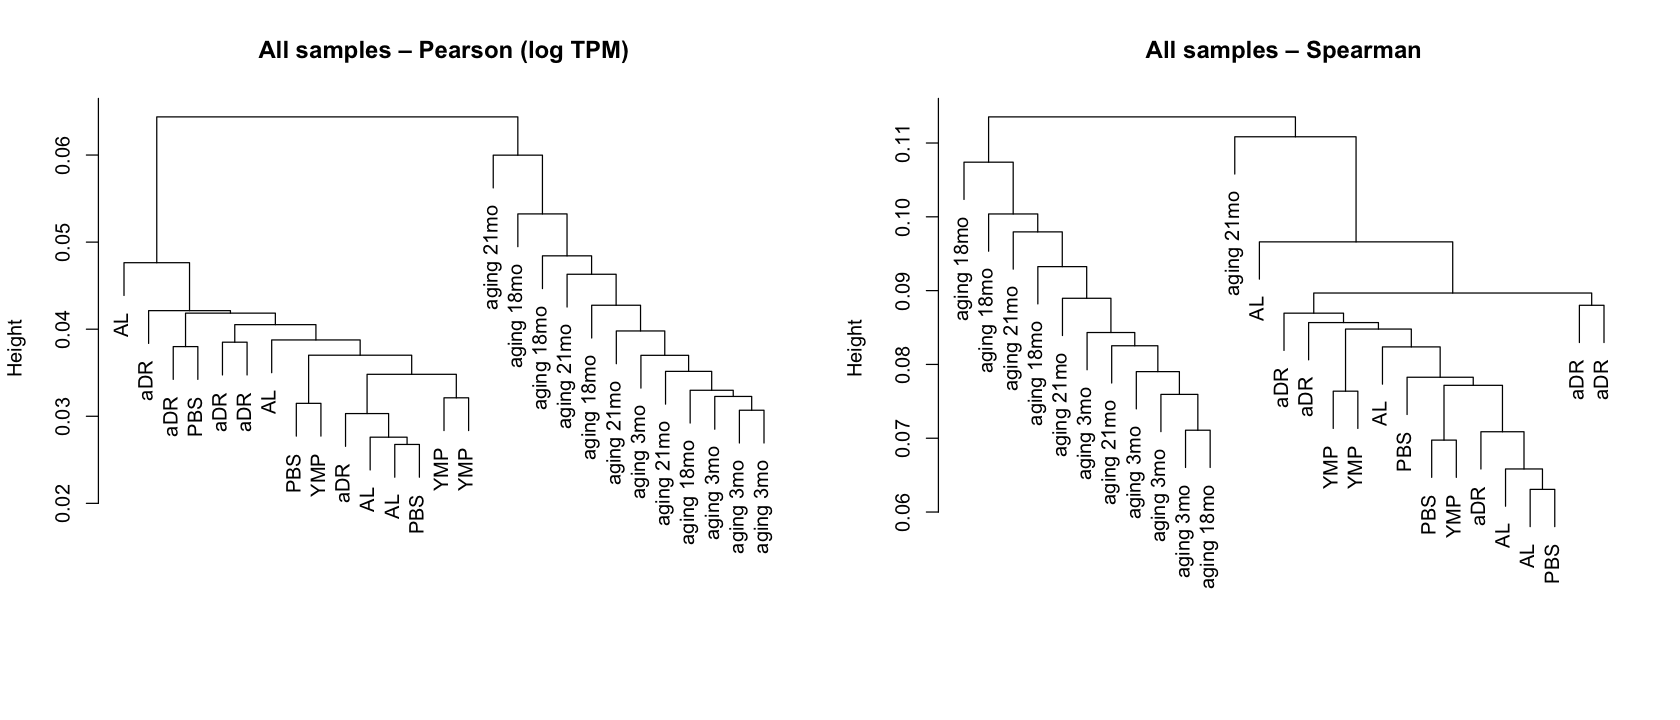

In [5]:
corr_pearson  <- cor(log1p(expr[expressed, ]))
corr_spearman <- cor(expr[expressed, ], method = "spearman")

hcl_pearson  <- hclust(as.dist(1 - corr_pearson))
hcl_spearman <- hclust(as.dist(1 - corr_spearman))

options(repr.plot.width = 14, repr.plot.height = 6)
layout(matrix(1:2, nrow = 1))
plot(hcl_pearson,  labels = meta$group, main = "All samples – Pearson (log TPM)", xlab = "", sub = "")
plot(hcl_spearman, labels = meta$group, main = "All samples – Spearman", xlab = "", sub = "")

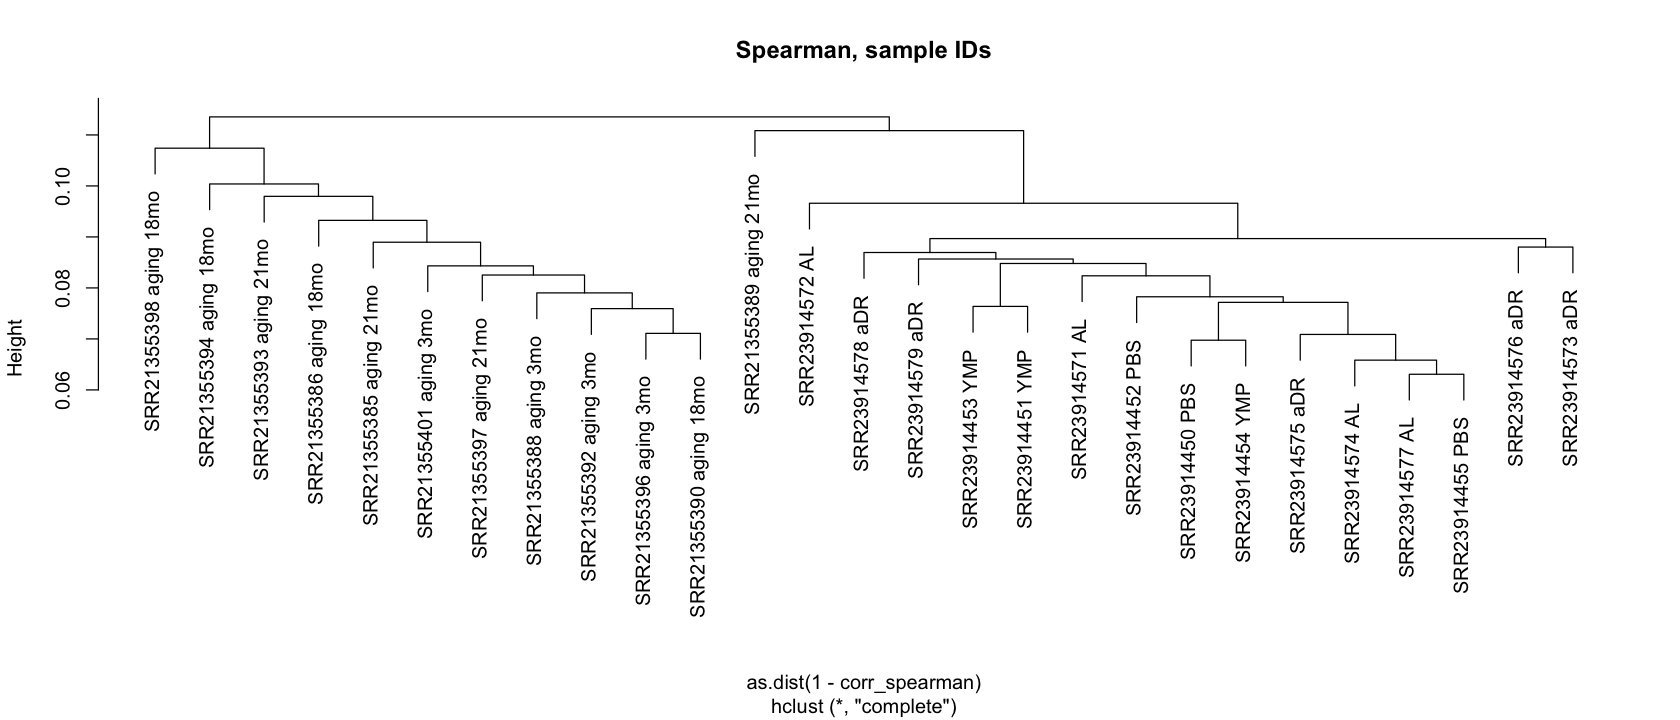

In [6]:
# Same tree, labelled with sample ID (to see which sample is which)
plot(hcl_spearman, labels = paste(meta$SRR, meta$group), main = "Spearman, sample IDs")

## PCA

[1] 18.3  7.6  5.8  5.0  4.4

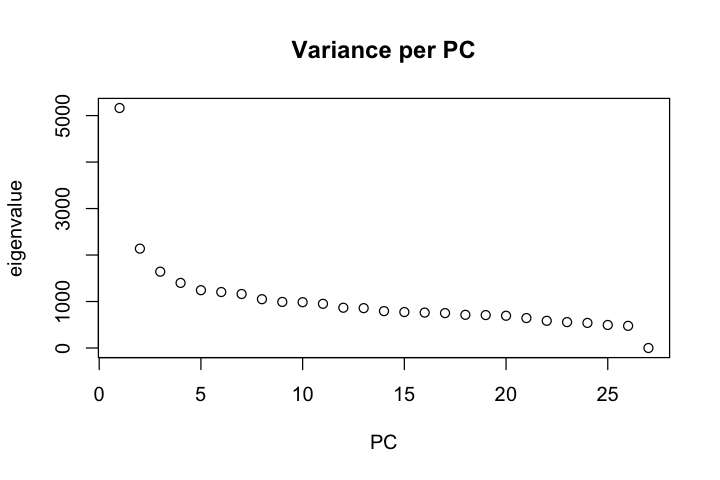

In [7]:
pca  <- prcomp(log1p(t(expr[expressed, ])), center = TRUE, scale. = TRUE)
eigs <- pca$sdev^2
pv   <- round(100 * eigs / sum(eigs), 1)
pv[1:5]

options(repr.plot.width = 6, repr.plot.height = 4)
plot(seq_along(eigs), eigs, xlab = "PC", ylab = "eigenvalue", main = "Variance per PC")

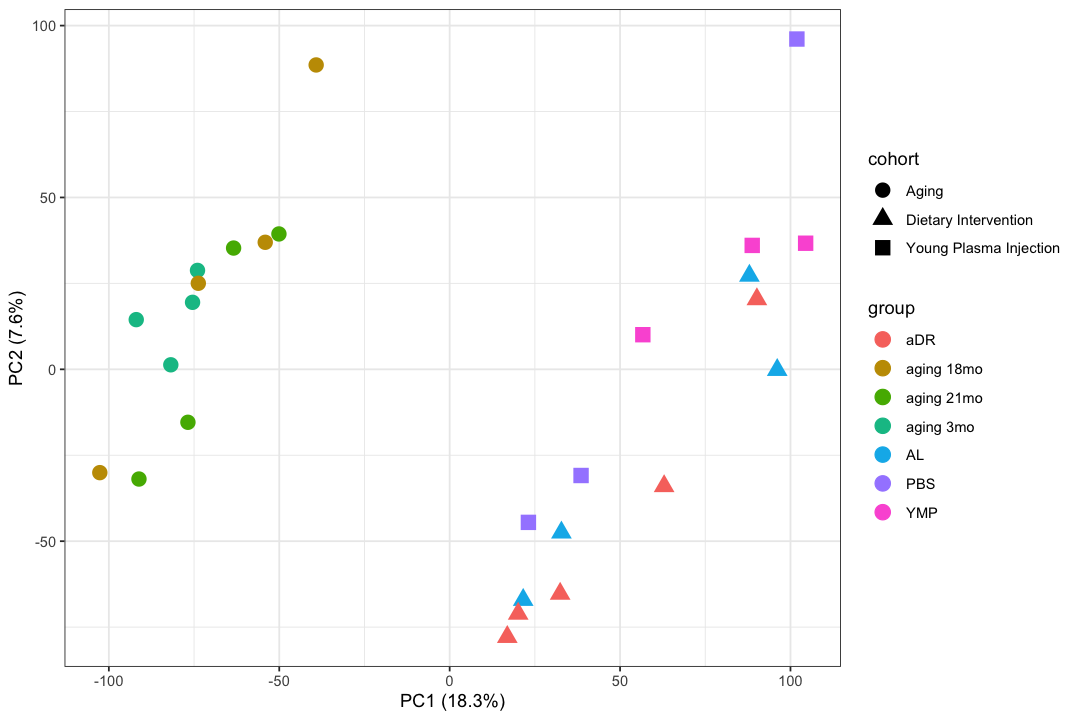

In [8]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(data.frame(pca$x, meta), aes(PC1, PC2, colour = group, shape = cohort)) +
  geom_point(size = 4) +
  labs(x = paste0("PC1 (", pv[1], "%)"), y = paste0("PC2 (", pv[2], "%)")) +
  theme_bw()

## Check the possible outlier SRR21355389

In [9]:
blood <- c("Hba-a1", "Hbb-bs", "S100a8", "S100a9")
blood_tpm <- expr[match(blood, meta_genes$symbol), meta$cohort == "Aging"]
rownames(blood_tpm) <- blood
round(blood_tpm)

,SRR21355401,SRR21355396,SRR21355392,SRR21355388,SRR21355398,SRR21355394,SRR21355390,SRR21355386,SRR21355397,SRR21355393,SRR21355389,SRR21355385
Hba-a1,11,319,56,13,170,164,122,21,54,0,4499,281
Hbb-bs,9,284,48,8,126,124,110,21,49,2,4242,288
S100a8,13,184,25,2,3,58,50,20,63,3,3959,229
S100a9,5,92,10,2,0,21,22,15,28,2,1756,85


## Separate the two datasets
PC1 and the trees split Aging from the two intervention cohorts (different experiments). From here on, each dataset is analysed on its own: genes are re-filtered within the dataset, then clustering and PCA are redone.

In [10]:
meta$dataset <- ifelse(meta$cohort == "Aging", "Aging", "Interventions")
table(meta$dataset, meta$group)

# Filter genes, cluster and run PCA for one dataset
compare_samples <- function(ds) {
  m <- meta[meta$dataset == ds, ]
  e <- expr[, m$SRR]
  keep <- rowMeans(e > 0) >= 0.5 | rowMeans(e) >= 1
  e <- e[keep, ]
  hcl_p <- hclust(as.dist(1 - cor(log1p(e))))
  hcl_s <- hclust(as.dist(1 - cor(e, method = "spearman")))
  pca <- prcomp(log1p(t(e)), center = TRUE, scale. = TRUE)
  pv  <- round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
  cat(ds, ":", ncol(e), "samples,", nrow(e), "expressed genes; PC1-3 =", pv[1:3], "%\n")
  list(meta = m, hcl_p = hcl_p, hcl_s = hcl_s, pca = data.frame(pca$x, m), pv = pv)
}

aging <- compare_samples("Aging")
interv <- compare_samples("Interventions")

               
                aDR aging 18mo aging 21mo aging 3mo AL PBS YMP
  Aging           0          4          4         4  0   0   0
  Interventions   5          0          0         0  4   3   3

Aging : 12 samples, 27077 expressed genes; PC1-3 = 13.9 12.7 11.1 %
Interventions : 15 samples, 30015 expressed genes; PC1-3 = 16.7 10.5 8.5 %


### Aging (3 / 18 / 21 months, 2 male + 2 female each)

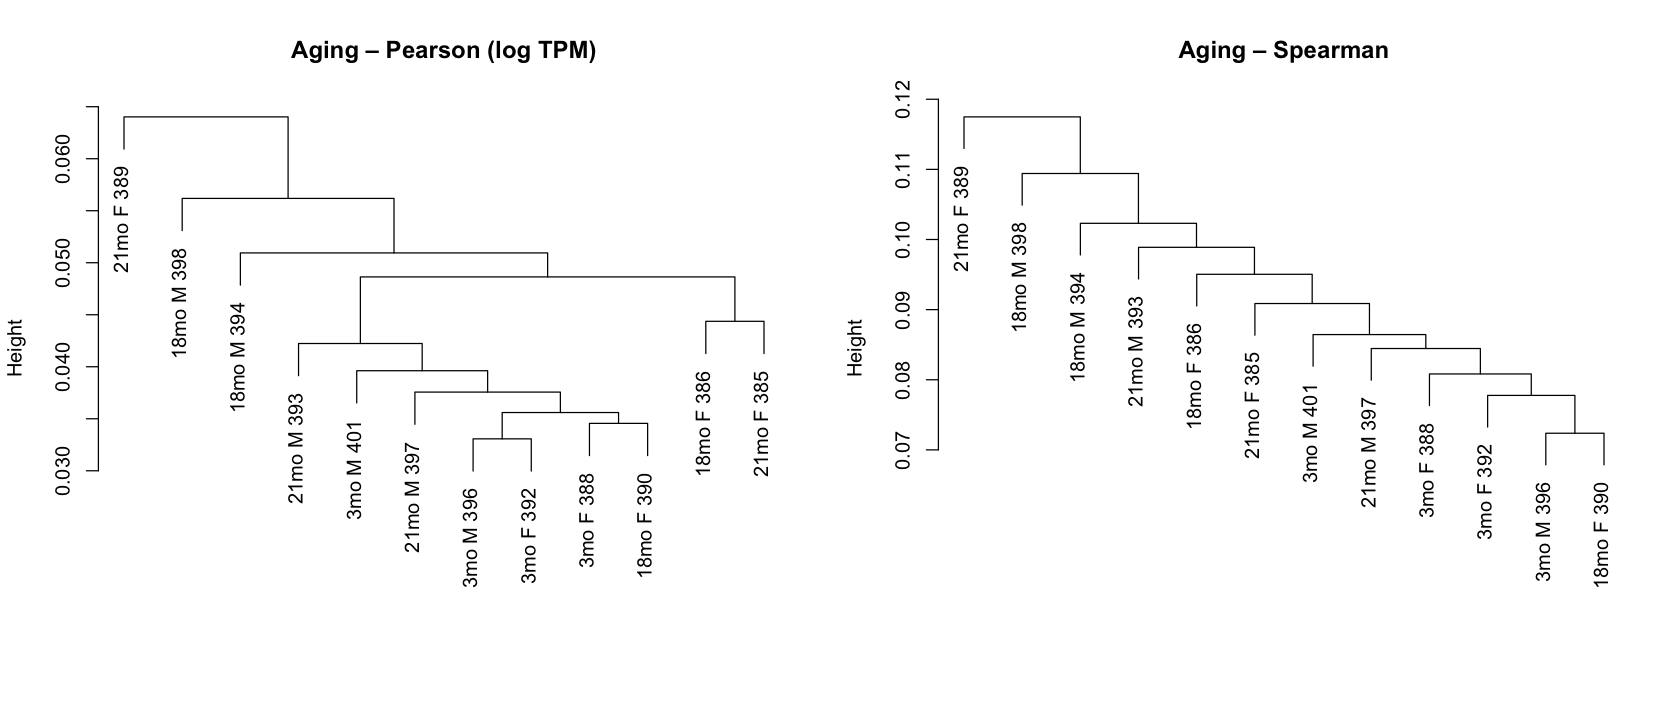

In [11]:
options(repr.plot.width = 14, repr.plot.height = 6)
# Label: age, sex (F/M), last 3 digits of the SRR id
lab <- paste(sub("aging ", "", aging$meta$group), toupper(substr(aging$meta$sex, 1, 1)),
             substr(aging$meta$SRR, 9, 11))
layout(matrix(1:2, nrow = 1))
plot(aging$hcl_p, labels = lab, main = "Aging – Pearson (log TPM)", xlab = "", sub = "")
plot(aging$hcl_s, labels = lab, main = "Aging – Spearman", xlab = "", sub = "")

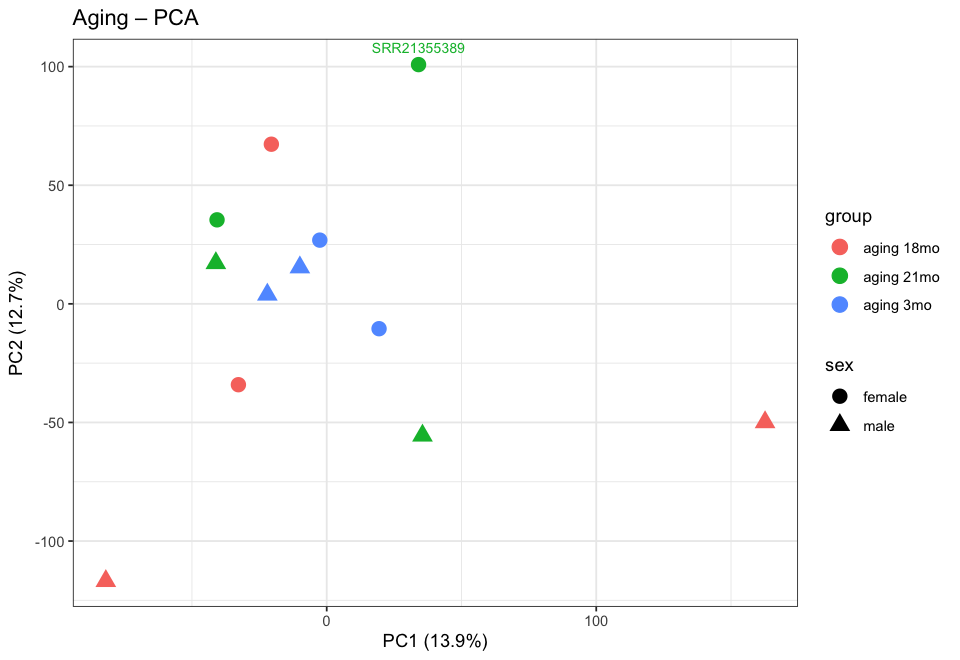

In [12]:
options(repr.plot.width = 8, repr.plot.height = 5.5)
ggplot(aging$pca, aes(PC1, PC2, colour = group, shape = sex)) +
  geom_point(size = 4) +
  geom_text(data = subset(aging$pca, SRR == "SRR21355389"), aes(label = SRR),
            vjust = -1.2, size = 3, show.legend = FALSE) +
  labs(x = paste0("PC1 (", aging$pv[1], "%)"), y = paste0("PC2 (", aging$pv[2], "%)"),
       title = "Aging – PCA") +
  theme_bw()

### Interventions (AL vs aDR, female; PBS vs YMP, male; all 19 months)

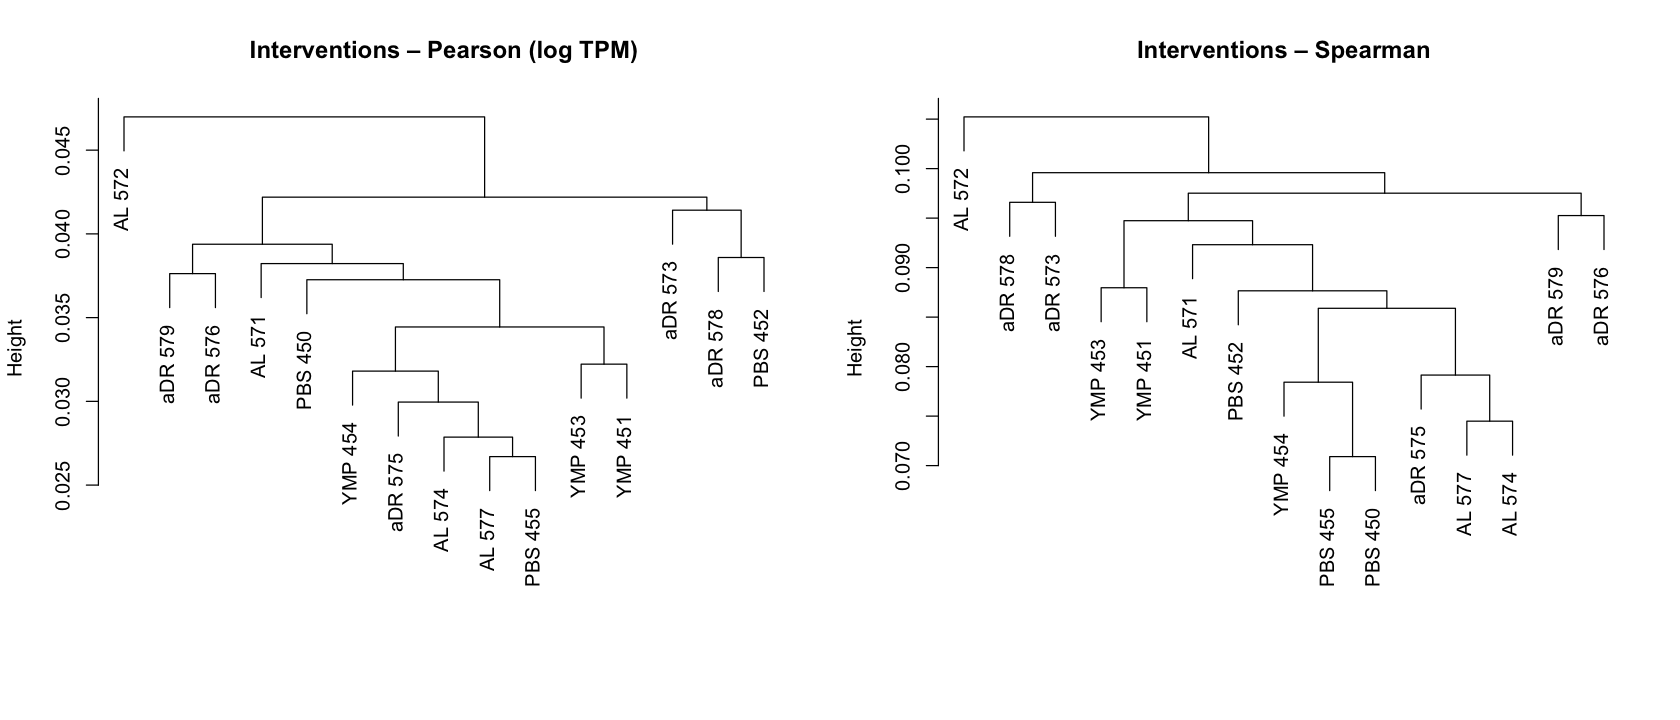

In [13]:
options(repr.plot.width = 14, repr.plot.height = 6)
# Label: group, last 3 digits of the SRR id
lab <- paste(interv$meta$group, substr(interv$meta$SRR, 9, 11))
layout(matrix(1:2, nrow = 1))
plot(interv$hcl_p, labels = lab, main = "Interventions – Pearson (log TPM)", xlab = "", sub = "")
plot(interv$hcl_s, labels = lab, main = "Interventions – Spearman", xlab = "", sub = "")

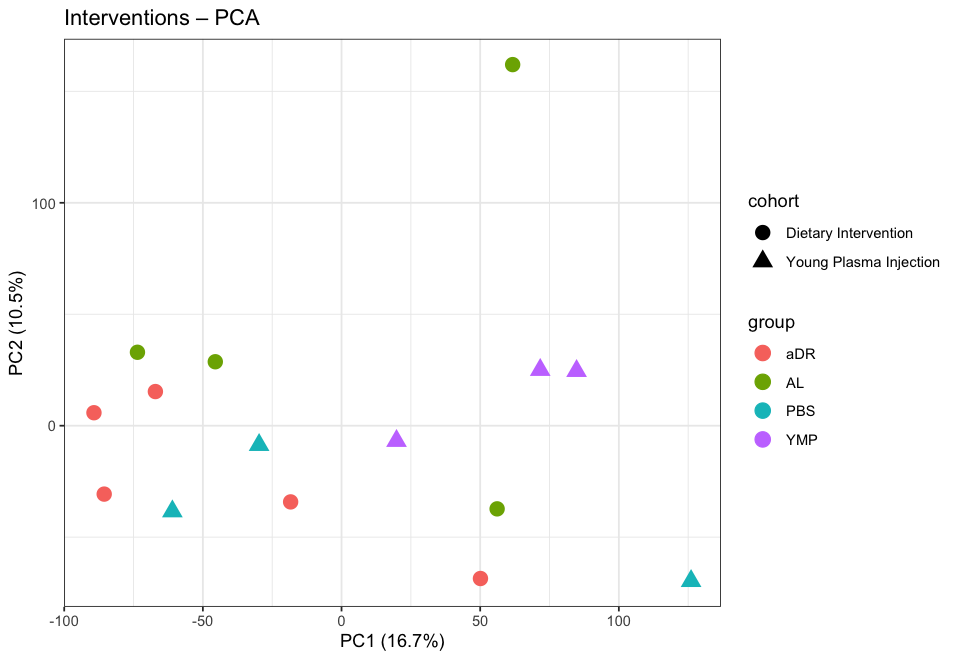

In [14]:
options(repr.plot.width = 8, repr.plot.height = 5.5)
ggplot(interv$pca, aes(PC1, PC2, colour = group, shape = cohort)) +
  geom_point(size = 4) +
  labs(x = paste0("PC1 (", interv$pv[1], "%)"), y = paste0("PC2 (", interv$pv[2], "%)"),
       title = "Interventions – PCA") +
  theme_bw()